In [1]:
import numpy as np
import math
import time
from numpy.linalg import solve

# analytical solution parameters
AA = 1
aa = 2.0*np.pi
bb = 3.0*np.pi

left_boundary = 0.0
right_boundary = 8.0

lamb = 4
def u(x):
    return AA * np.sin(bb * (x + 0.05)) * np.cos(aa * (x + 0.05)) + 2.0

def d2u_dx2(x):
    return -AA*(aa*aa+bb*bb)*np.sin(bb*(x+0.05))*np.cos(aa*(x+0.05))\
           -2.0*AA*aa*bb*np.cos(bb*(x+0.05))*np.sin(aa*(x+0.05))

def f(x):
    return(d2u_dx2(x) + lamb*u(x))

vanal_u = np.vectorize(u)
vanal_f = np.vectorize(f)

In [2]:
# calculate the matrix A,f in linear equations system 'Au=f'
def cal_matrix(N, points):
    A = np.zeros((N+1,N+1),dtype=np.float64)
    dx = (right_boundary - left_boundary)/N
    for i in range(1,N):
        A[i,i-1] = 1/(dx**2)
        A[i,i] = lamb - 2/(dx**2)
        A[i,i+1] = 1/(dx**2)
    A[0,0] = 1.0
    A[N,N] = 1.0
    f = np.zeros((N+1,1),dtype=np.float64)
    f[0,0] = u(points[0])
    f[1:N] = vanal_f(points[1:N]).reshape((-1,1))
    f[N] = u(points[-1])
    return(A,f)

***********************
N = M = 100
L_infty= 0.4038518006879608 L_2= 0.6818204170644571
***********************
N = M = 200
L_infty= 0.10009073936892454 L_2= 0.16727260903614227
***********************
N = M = 400
L_infty= 0.02486975848355799 L_2= 0.041674282365398385
***********************
N = M = 800
L_infty= 0.006221760356481809 L_2= 0.010413267706642002
***********************
N = M = 1600
L_infty= 0.0015548590705942722 L_2= 0.0026033988645023766


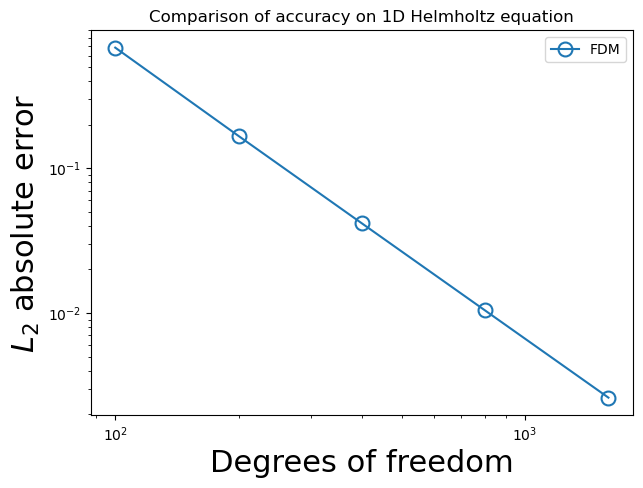

In [3]:
# calculate the l^{inf}-norm and l^{2}-norm error for u
def test(points, u):
    true_values = vanal_u(points)
    numerical_values = u
    epsilon = true_values - numerical_values
    epsilon = np.maximum(epsilon, -epsilon)
    error_inf = epsilon.max()
    error_l2 = math.sqrt(8*sum(epsilon*epsilon)/len(epsilon))
    print('L_infty=',error_inf,'L_2=',error_l2)
    return(error_l2)

def error_plot(multi_Errors):
    import matplotlib.pyplot as plt
    plt.figure(figsize=[7, 5])
    plt.tick_params(labelsize=10)
    font2 = {
    'weight' : 'normal',
    'size'   : 22,
    }
    plt.xlabel('Degrees of freedom',font2)
    plt.ylabel('$L_2$ absolute error',font2)
    plt.xscale('log')
    plt.yscale('log')
    Label = ['FDM','PINN','RFM']
    for i in range(len(multi_Errors)):
        Error = multi_Errors[i]
        plt.plot(Error[:,0], Error[:,1], \
                 lw=1.5, ls='-', clip_on=False,\
                 marker='o', markersize=10, \
                 label = Label[i],\
                 markerfacecolor='none',\
                 markeredgewidth=1.5)
    plt.legend()
    plt.title("Comparison of accuracy on 1D Helmholtz equation")
    plt.show()

def time_plot(multi_Errors):
    import matplotlib.pyplot as plt
    plt.figure(figsize=[7, 5])
    plt.tick_params(labelsize=10)
    font2 = {
    'weight' : 'normal',
    'size'   : 22,
    }
    plt.xlabel('Degrees of freedom',font2)
    plt.ylabel('Solving time',font2)
    Label = ['FDM','PINN','RFM']
    for i in range(len(multi_Errors)):
        Error = multi_Errors[i]
        plt.plot(Error[:,0], Error[:,2], \
                 lw=1.5, ls='-', clip_on=False,\
                 marker='o', markersize=10, \
                 label = Label[i],\
                 markerfacecolor='none',\
                 markeredgewidth=1.5)
    plt.legend()
    plt.title("Comparison of efficiency on 1D Helmholtz equation")
    plt.show()
    
def main(N):
    time_begin = time.time()
    points = np.linspace(0, 8.0, N+1)
    A,f = cal_matrix(N,points)
    u = solve(A,f).reshape((-1))
    error = test(points, u)
    time_end = time.time()
    return(error, time_end - time_begin)

if __name__ == '__main__':
    FDM_Error = np.zeros([5,3])
    for i in range(5):
        N = int(100 * 2**i)
        print('***********************')
        print("N = M =",N)
        FDM_Error[i,0] = N
        FDM_Error[i,1], FDM_Error[i,2] = main(N)
    
    error_plot([FDM_Error])

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.autograd import Variable
torch.set_default_dtype(torch.float64)

R_m = 1.0
def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.uniform_(m.weight, a = -R_m, b = R_m)
        nn.init.uniform_(m.bias, a = -R_m, b = R_m)

# network definition
class Network(nn.Module):
    def __init__(self, d, M):
        super(Network, self).__init__()
        self.fc_layer = nn.Sequential(nn.Linear(d, M, bias=True),nn.Tanh())
        self.output_layer = nn.Linear(M, 1, bias = False)
        
    def forward(self, x):
        h = self.fc_layer(x)
        out = self.output_layer(h)
        return out

In [5]:
# loss definition
class Loss():
    def __init__(self, net, left_boundary, right_boundary):
        self.net = net
        self.left_boundary = left_boundary
        self.right_boundary = right_boundary

    def sample(self, N):
        x = torch.tensor(np.float64(np.linspace(self.left_boundary, self.right_boundary, N+1)[1:N]),requires_grad=True).reshape(-1,1)
        x_boundary_left = torch.ones([1],requires_grad=True) * self.left_boundary
        x_boundary_right = torch.ones([1],requires_grad=True) * self.right_boundary
        return x, x_boundary_left, x_boundary_right

    def loss_func(self, N):
        # helmholtz equation
        x, x_boundary_left, x_boundary_right = self.sample(N)
        x = Variable(x, requires_grad=True)
        y = self.net(x)
        dx = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(self.net(x)), create_graph=True)[0].reshape(-1, 1)
        dxx = torch.autograd.grad(dx, x, grad_outputs=torch.ones_like(dx), create_graph=True)[0].reshape(-1, 1)
        
        f = -AA*(aa*aa+bb*bb)*torch.sin(bb*(x+0.05))*torch.cos(aa*(x+0.05))\
           -2.0*AA*aa*bb*torch.cos(bb*(x+0.05))*torch.sin(aa*(x+0.05))\
           -lamb * (AA * torch.sin(bb * (x + 0.05)) * torch.cos(aa * (x + 0.05)) + 2.0)
        diff_error = (dxx - lamb*self.net(x) - f.reshape(-1, 1))**2
        
        # boundary condition
        bd_left_error = (self.net(x_boundary_left) - (AA * torch.sin(bb * (x_boundary_left + 0.05)) * torch.cos(aa * (x_boundary_left + 0.05)) + 2.0)) ** 2
        bd_right_error = (self.net(x_boundary_right) - (AA * torch.sin(bb * (x_boundary_right + 0.05)) * torch.cos(aa * (x_boundary_right + 0.05)) + 2.0)) ** 2
        
        return torch.mean(diff_error + bd_left_error + bd_right_error)

In [6]:
# training process
class Train():
    def __init__(self, net, loss, N):
        self.errors = []
        self.N = N
        self.net = net
        self.model = loss

    def train(self, epoch, lr):
        optimizer = optim.Adam(filter(lambda p: p.requires_grad, self.net.parameters()), lr)
        avg_loss = 0
        for e in range(epoch):
            optimizer.zero_grad()
            loss = self.model.loss_func(self.N)
            avg_loss = avg_loss + float(loss.item())
            loss.backward()
            optimizer.step()
            if e % 50 == 49:
                loss = avg_loss/50
                #print("Epoch {} - lr {} -  loss: {}".format(e, lr, loss))
                avg_loss = 0
                error = self.model.loss_func(self.N)
                self.errors.append(error.detach())

***********************
N = M = 100
L_infty= 0.2590852531198111 L_2= 0.13539993313765022


C:\Users\黄南樵\AppData\Local\Temp\ipykernel_5752\2388823797.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  error_l2 = math.sqrt(8*sum(epsilon*epsilon)/len(epsilon))


***********************
N = M = 200
L_infty= 0.0072886229198605434 L_2= 0.005349031979914825
***********************
N = M = 400
L_infty= 0.016148476097743725 L_2= 0.011604160001864174
***********************
N = M = 800
L_infty= 0.3041003718441777 L_2= 0.16392527019266254
***********************
N = M = 1600
L_infty= 1.0546022997930553 L_2= 0.45773904690108014


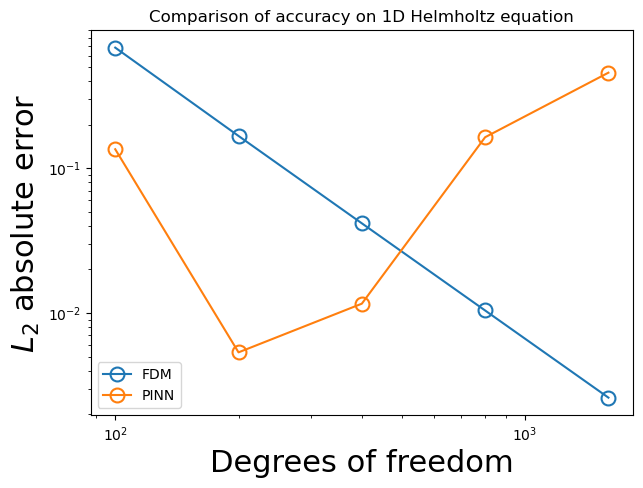

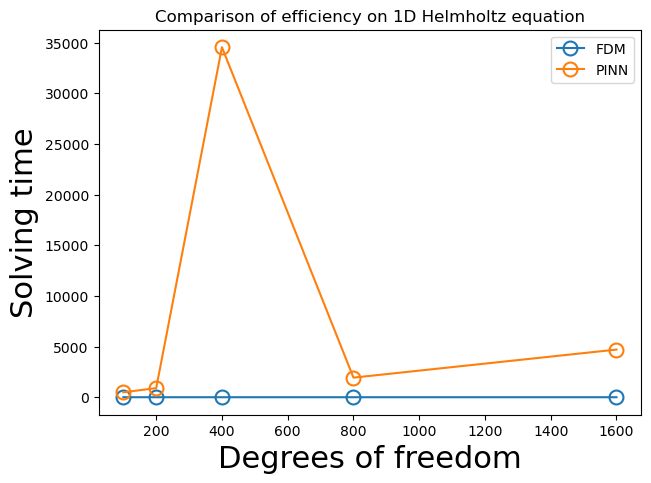

In [7]:
# test process
def Test(net, N):
    # PINN testing process
    points = np.linspace(left_boundary, right_boundary, N+1, dtype=np.float64)[:N]
    true_value = u(points).reshape([-1,1])
    numerical_value = net(torch.tensor(points,requires_grad=False).reshape([-1,1])).detach().cpu().numpy()
    epsilon = true_value - numerical_value
    epsilon = np.abs(epsilon)
    error_inf = epsilon.max()
    error_l2 = math.sqrt(8*sum(epsilon*epsilon)/len(epsilon))
    print('L_infty=',error_inf,'L_2=',error_l2)
    return(error_l2)

if __name__=="__main__":
    PINN_Error = np.zeros([5,3])
    for i in range(5):
        time_begin = time.time()
        N = int(100 * 2**i) # number of collocation points
        M = int(100 * 2**i) # number of basis
        
        # PINN model define and initialization
        net = Network(1, M)
        net.fc_layer = net.fc_layer.apply(weights_init)
        
        # PINN training process
        FREEZE = False
        if FREEZE == True:
            net.fc_layer.requires_grad_(False)
            loss = Loss(net, left_boundary, right_boundary)
            train = Train(net, loss, N)
            train.train(epoch=10**2, lr=0.001)
            train.train(epoch=4*10**2, lr=0.0001)
        else:
            loss = Loss(net, left_boundary, right_boundary)
            train = Train(net, loss, N)
            train.train(epoch=5*10**3, lr=0.1)
            train.train(epoch=10**4, lr=0.01)
            train.train(epoch=10**4, lr=0.001)
            train.train(epoch=2*10**4, lr=0.0001)
        
        # PINN testing process
        print('***********************')
        print("N = M =",N)
        PINN_Error[i,0] = N
        PINN_Error[i,1] = Test(net, N)
        time_end = time.time()
        PINN_Error[i,2] = time_end - time_begin

    error_plot([FDM_Error, PINN_Error])
    time_plot([FDM_Error, PINN_Error])

In [8]:
# computational domain
X_min = 0.0
X_max = 8.0

# random initialization for parameters
def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.uniform_(m.weight, a = -R_m, b = R_m)
        nn.init.uniform_(m.bias, a = -R_m, b = R_m)

# random feature basis when using \psi^{a} as PoU function
class RFM_rep_a(nn.Module):
    def __init__(self, d, J_n, x_max, x_min):
        super(RFM_rep_a, self).__init__()
        self.d = d
        self.J_n = J_n
        self.r = (x_max - x_min) / 2.0
        self.x_c = (x_max + x_min)/2
        self.phi = nn.Sequential(nn.Linear(self.d, self.J_n, bias=True),nn.Tanh())

    def forward(self,x):
        x = (x - self.x_c) / self.r
        x = self.phi(x)
        return x

# random feature basis when using \psi^{b} as PoU function
class RFM_rep_b(nn.Module):
    def __init__(self, d, J_n, x_max, x_min):
        super(RFM_rep_b, self).__init__()
        self.d = d
        self.J_n = J_n
        self.n = x_min/(X_max-X_min) * M_p
        self.r = (x_max - x_min) / 2.0
        self.x_0 = (x_max + x_min)/2
        self.phi = nn.Sequential(nn.Linear(self.d, self.J_n, bias=True),nn.Tanh())

    def forward(self,x):
        d = (x - self.x_0) / self.r
        psi = ((d <= -3/4) & (d > -5/4)) * (1+torch.sin(2*np.pi*d))/2 + ((d <= 3/4) & (d > -3/4)) * 1.0 + ((d <= 5/4) & (d > 3/4)) * (1-torch.sin(2*np.pi*d))/2
        y = self.phi(d)
        if self.n == 0:
            psi = ((d <= 3/4) & (d > -1)) * 1.0 + ((d <= 5/4) & (d > 3/4)) * (1-torch.sin(2*np.pi*d))/2
        elif self.n == M_p-1:
            psi = ((d <= -3/4) & (d > -5/4)) * (1+torch.sin(2*np.pi*d))/2 + ((d <= 1) & (d > -3/4)) * 1.0
        else:
            psi = ((d <= -3/4) & (d > -5/4)) * (1+torch.sin(2*np.pi*d))/2 + ((d <= 3/4) & (d > -3/4)) * 1.0 + ((d <= 5/4) & (d > 3/4)) * (1-torch.sin(2*np.pi*d))/2
        return(psi*y)

# predefine the random feature functions in each PoU region
def pre_define(M_p,J_n):
    models = []
    for n in range(M_p):
        x_min = (X_max-X_min)/M_p * n + X_min
        x_max = (X_max-X_min)/M_p * (n+1) + X_min
        model = RFM_rep_a(d = 1, J_n = J_n, x_min = x_min, x_max = x_max)
        model = model.apply(weights_init)
        model = model.double()
        for param in model.parameters():
            param.requires_grad = False
        models.append(model)
    return(models)

# computational domain
X_min = 0.0
X_max = 8.0

# random initialization for parameters
def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.uniform_(m.weight, a = -R_m, b = R_m)
        nn.init.uniform_(m.bias, a = -R_m, b = R_m)

# random feature basis when using \psi^{a} as PoU function
class RFM_rep_a(nn.Module):
    def __init__(self, d, J_n, x_max, x_min):
        super(RFM_rep_a, self).__init__()
        self.d = d
        self.J_n = J_n
        self.r = (x_max - x_min) / 2.0
        self.x_c = (x_max + x_min)/2
        self.phi = nn.Sequential(nn.Linear(self.d, self.J_n, bias=True),nn.Tanh())

    def forward(self,x):
        x = (x - self.x_c) / self.r
        x = self.phi(x)
        return x

# random feature basis when using \psi^{b} as PoU function
class RFM_rep_b(nn.Module):
    def __init__(self, d, J_n, x_max, x_min):
        super(RFM_rep_b, self).__init__()
        self.d = d
        self.J_n = J_n
        self.n = x_min/(X_max-X_min) * M_p
        self.r = (x_max - x_min) / 2.0
        self.x_0 = (x_max + x_min)/2
        self.phi = nn.Sequential(nn.Linear(self.d, self.J_n, bias=True),nn.Tanh())

    def forward(self,x):
        d = (x - self.x_0) / self.r
        psi = ((d <= -3/4) & (d > -5/4)) * (1+torch.sin(2*np.pi*d))/2 + ((d <= 3/4) & (d > -3/4)) * 1.0 + ((d <= 5/4) & (d > 3/4)) * (1-torch.sin(2*np.pi*d))/2
        y = self.phi(d)
        if self.n == 0:
            psi = ((d <= 3/4) & (d > -1)) * 1.0 + ((d <= 5/4) & (d > 3/4)) * (1-torch.sin(2*np.pi*d))/2
        elif self.n == M_p-1:
            psi = ((d <= -3/4) & (d > -5/4)) * (1+torch.sin(2*np.pi*d))/2 + ((d <= 1) & (d > -3/4)) * 1.0
        else:
            psi = ((d <= -3/4) & (d > -5/4)) * (1+torch.sin(2*np.pi*d))/2 + ((d <= 3/4) & (d > -3/4)) * 1.0 + ((d <= 5/4) & (d > 3/4)) * (1-torch.sin(2*np.pi*d))/2
        return(psi*y)

# predefine the random feature functions in each PoU region
def pre_define(M_p,J_n):
    models = []
    for n in range(M_p):
        x_min = (X_max-X_min)/M_p * n + X_min
        x_max = (X_max-X_min)/M_p * (n+1) + X_min
        model = RFM_rep_a(d = 1, J_n = J_n, x_min = x_min, x_max = x_max)
        model = model.apply(weights_init)
        model = model.double()
        for param in model.parameters():
            param.requires_grad = False
        models.append(model)
    return(models)

In [9]:
# analytical solution parameters
AA = 1
aa = 2.0*np.pi
bb = 3.0*np.pi
lamb = 4

vanal_u = np.vectorize(u)
vanal_d2u_dx2 = np.vectorize(d2u_dx2)

def F(points, lamb):
    return(vanal_d2u_dx2(points) - lamb * vanal_u(points))

import math
import matplotlib.pyplot as plt
# calculate the l^{infty}-norm and l^{2}-norm error for u
def test(models,M_p,J_n,Q,w,plot = False):
    epsilon = []
    true_values = []
    numerical_values = []
    test_Q = 2*Q
    for n in range(M_p):
        points = torch.tensor(np.linspace((X_max-X_min)/M_p * n + X_min, (X_max-X_min)/M_p * (n+1) + X_min, test_Q+1),requires_grad=False).reshape([-1,1])
        out = models[n](points)
        values = out.detach().numpy()
        true_value = vanal_u(points.numpy()).reshape([-1,1])
        numerical_value = np.dot(values, w[n*J_n:(n+1)*J_n,:])
        true_values.extend(true_value)
        numerical_values.extend(numerical_value)
        epsilon.extend(true_value - numerical_value)
    true_values = np.array(true_values)
    numerical_values = np.array(numerical_values)
    epsilon = np.array(epsilon)
    epsilon = np.maximum(epsilon, -epsilon)
    print('R_m=%s,M_p=%s,J_n=%s,Q=%s'%(R_m,M_p,J_n,Q))
    print('L_infty error =',epsilon.max(),', L_2 error =',math.sqrt(8*sum(epsilon*epsilon)/len(epsilon)))
    x = [((X_max - X_min)/M_p)*i / test_Q  for i in range(M_p*(test_Q+1))]
    return(math.sqrt((X_max-X_min)*sum(epsilon*epsilon)/len(epsilon)))

if __name__ == '__main__':
    lamb = 4
    R_m = 3
    J_n = 50 # the number of basis functions per PoU region
    Q = 50 # the number of collocation pointss per PoU region
    RFM_Error = np.zeros([5,3])
    for i in range(5): # the number of PoU regions
        M_p = 2*(2**i)
        RFM_Error[i,0] = int(M_p * J_n)
        RFM_Error[i,1], RFM_Error[i,2] = main(M_p,J_n,Q,lamb)
    error_plot([FDM_Error, PINN_Error, RFM_Error])
    time_plot([FDM_Error, PINN_Error, RFM_Error])

TypeError: main() takes 1 positional argument but 4 were given